### Cargando datos con Polars

In [ ]:
import polars as pl
import urllib.parse
from datetime import datetime, timezone

# Define la fecha final para el filtro. Ahora se establecerá en la fecha y hora actuales (UTC).
current_utc_time = datetime.now(timezone.utc)
end_date_filter = current_utc_time.strftime('%Y-%m-%dT%H:%M:%S')

# La URL base y la condición de filtro ahora usarán la fecha dinámica.
base_url = "https://www.datos.gov.co/resource/eh75-8ah6.csv"
filter_condition = f"fecha_despacho between '2025-01-01T00:00:00' and '{end_date_filter}'"
encoded_filter_condition = urllib.parse.quote(filter_condition)

# Construir la URL con el filtro y un límite alto para obtener más datos
url_polars = f"{base_url}?$where={encoded_filter_condition}&$limit=15000000" # Aumentamos el límite a 500,000 para obtener todos los datos

# Cargar los datos usando Polars
pl_df = pl.read_csv(url_polars)

print("DataFrame cargado con Polars:")
print(pl_df.head())

DataFrame cargado con Polars:
shape: (5, 10)
┌───────────┬───────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬──────────┐
│ terminal  ┆ clase_veh ┆ nivel_ser ┆ municipio ┆ … ┆ hora_desp ┆ tipo_desp ┆ despachos ┆ pasajero │
│ ---       ┆ iculo     ┆ vicio     ┆ _origen_r ┆   ┆ acho      ┆ acho      ┆ ---       ┆ s        │
│ str       ┆ ---       ┆ ---       ┆ uta       ┆   ┆ ---       ┆ ---       ┆ i64       ┆ ---      │
│           ┆ str       ┆ str       ┆ ---       ┆   ┆ i64       ┆ str       ┆           ┆ i64      │
│           ┆           ┆           ┆ i64       ┆   ┆           ┆           ┆           ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪══════════╡
│ T.T. DE   ┆ BUS       ┆ BASICO    ┆ 5001      ┆ … ┆ 18        ┆ TRANSITO  ┆ 1         ┆ 38       │
│ HONDA     ┆           ┆           ┆           ┆   ┆           ┆           ┆           ┆          │
│ T.T. DE   ┆ MICROBUS  ┆ LUJO      ┆ 17001   

In [ ]:
print(f"El DataFrame tiene {pl_df.shape[0]} filas (datos).")

El DataFrame tiene 14796493 filas (datos).


Para mantener la compatibilidad con el resto del código que ya utiliza Pandas, convertiremos el DataFrame de Polars de nuevo a Pandas. Si deseas continuar el análisis con Polars, házmelo saber.

In [ ]:
# Convertir el DataFrame de Polars a Pandas
df = pl_df.to_pandas()

print("DataFrame convertido a Pandas (df):")
print(df.head())


DataFrame convertido a Pandas (df):
               terminal clase_vehiculo nivel_servicio  municipio_origen_ruta  \
0         T.T. DE HONDA            BUS         BASICO                   5001   
1     T.T. DE MANIZALES       MICROBUS           LUJO                  17001   
2          T.T. DE CALI         BUSETA         BASICO                  76001   
3  T.T. DE MEDELLÍN SUR       MICROBUS         BASICO                   5001   
4       T.T. DE YARUMAL       MICROBUS           LUJO                   5887   

   municipio_destino_ruta           fecha_despacho  hora_despacho  \
0                   11001  2025-01-01T00:00:00.000             18   
1                   63001  2025-01-01T00:00:00.000             14   
2                   47570  2025-01-01T00:00:00.000             15   
3                    5030  2025-01-01T00:00:00.000             14   
4                    5001  2025-01-01T00:00:00.000              9   

  tipo_despacho  despachos  pasajeros  
0      TRANSITO          1  

In [ ]:
df.describe()

,municipio_origen_ruta,municipio_destino_ruta,hora_despacho,despachos,pasajeros
count,1.479649e+07,1.479649e+07,1.479649e+07,1.479649e+07,1.479649e+07
mean,3.662026e+04,3.861971e+04,1.201584e+01,1.035821e+00,9.584746e+00
std,2.764533e+04,2.673384e+04,4.949197e+00,2.567219e-01,9.080566e+00
min,5.001000e+03,5.001000e+03,0.000000e+00,1.000000e+00,0.000000e+00
25%,1.100100e+04,1.517600e+04,8.000000e+00,1.000000e+00,4.000000e+00
50%,2.300100e+04,2.577200e+04,1.200000e+01,1.000000e+00,8.000000e+00
75%,6.600100e+04,6.640000e+04,1.600000e+01,1.000000e+00,1.300000e+01
max,9.977300e+04,9.977300e+04,2.300000e+01,1.700000e+01,6.400000e+02


Aca hacemos la tranformacion al tipo de dato en las columnas de fecha y horas

In [ ]:
import pandas as pd
df['fecha_despacho'] = pd.to_datetime(df['fecha_despacho'])
print("Columna 'fecha_despacho' convertida a tipo datetime.")

# Convertir la columna 'hora_despacho' a tipo tiempo
df['hora_despacho'] = pd.to_datetime(df['hora_despacho'], unit='h').dt.time
print("Columna 'hora_despacho' convertida a tipo tiempo.")

Columna 'fecha_despacho' convertida a tipo datetime.
Columna 'hora_despacho' convertida a tipo tiempo.


Aca borramos los registros duplicados y nulos

In [ ]:
initial_rows = df.shape[0]
df.drop_duplicates(inplace=True)
duplicates_removed_rows = df.shape[0]

print(f"Se eliminaron {initial_rows - duplicates_removed_rows} filas duplicadas.")
print(f"El DataFrame ahora tiene {duplicates_removed_rows} filas después de eliminar duplicados.")

# Eliminar filas con valores nulos
initial_rows_before_null_removal = df.shape[0]
df.dropna(inplace=True)
final_rows = df.shape[0]

print(f"Se eliminaron {initial_rows_before_null_removal - final_rows} filas con valores nulos.")
print(f"El DataFrame ahora tiene {final_rows} filas después de eliminar duplicados y nulos.")

Se eliminaron 2704312 filas duplicadas.
El DataFrame ahora tiene 12092181 filas después de eliminar duplicados.
Se eliminaron 0 filas con valores nulos.
El DataFrame ahora tiene 12092181 filas después de eliminar duplicados y nulos.


Descargamos el csv para hacer la hacerle el ETL con Pentaho y unir informaciona adicional

In [ ]:
df.info()

# --- Opciones para descargar los datos ---

# Para descargar en formato CSV:
df.to_csv('datos_despacho.csv', index=False)
print('DataFrame exportado a datos_despacho.csv')

# Para descargar en formato XLSX (Excel):
# Necesitarás tener instalada la librería openpyxl: pip install openpyxl
# df.to_excel('datos_despacho.xlsx', index=False)
# print('DataFrame exportado a datos_despacho.xlsx')

<class 'pandas.core.frame.DataFrame'>
Index: 12092181 entries, 0 to 14796492
Data columns (total 10 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   terminal                object        
 1   clase_vehiculo          object        
 2   nivel_servicio          object        
 3   municipio_origen_ruta   int64         
 4   municipio_destino_ruta  int64         
 5   fecha_despacho          datetime64[ns]
 6   hora_despacho           object        
 7   tipo_despacho           object        
 8   despachos               int64         
 9   pasajeros               int64         
dtypes: datetime64[ns](1), int64(4), object(5)
memory usage: 1014.8+ MB
DataFrame exportado a datos_despacho.csv


In [ ]:
oldest_record = df['fecha_despacho'].min()
most_recent_record = df['fecha_despacho'].max()

print(f"Fecha de despacho más antigua: {oldest_record}")
print(f"Fecha de despacho más reciente: {most_recent_record}")

Fecha de despacho más antigua: 2025-01-01 00:00:00
Fecha de despacho más reciente: 2026-04-07 00:00:00


## Análisis Cuantitativo: Diagrama de Correlación

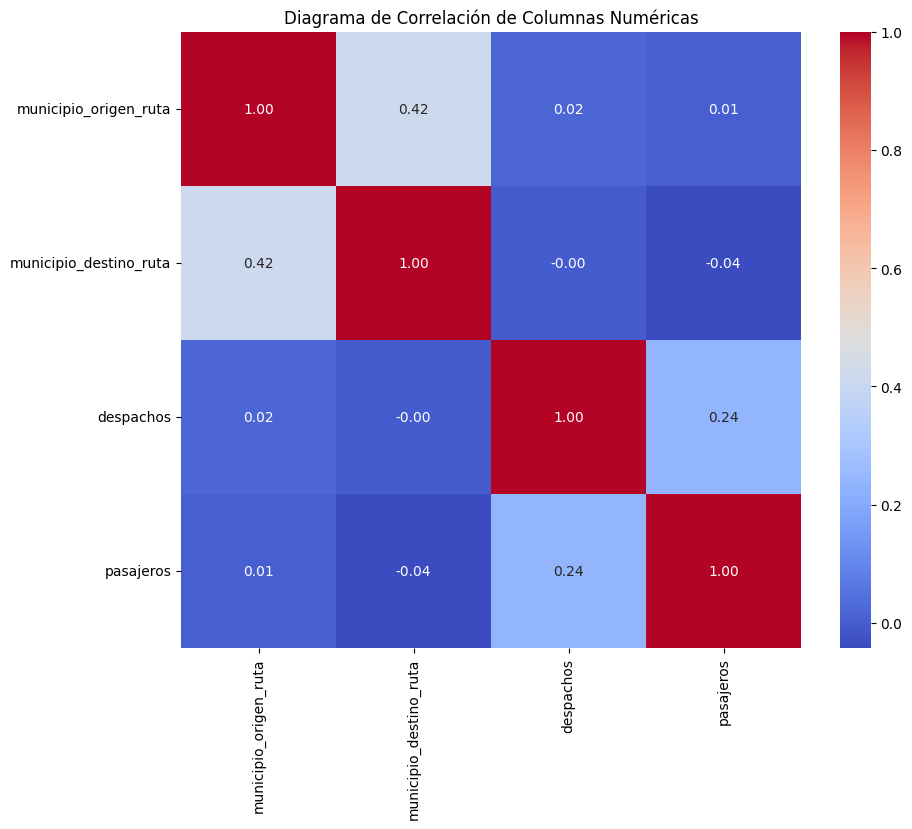

La matriz de correlación muestra las relaciones lineales entre pares de variables numéricas. Valores cercanos a 1 o -1 indican una fuerte correlación positiva o negativa, respectivamente. Valores cercanos a 0 indican poca o ninguna correlación lineal.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar solo las columnas numéricas para el cálculo de correlación
numerical_df = df.select_dtypes(include=['number'])

# Calcular la matriz de correlación
correlation_matrix = numerical_df.corr()

# Crear un mapa de calor para visualizar la matriz de correlación
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Diagrama de Correlación de Columnas Numéricas')
plt.show()

print("La matriz de correlación muestra las relaciones lineales entre pares de variables numéricas. Valores cercanos a 1 o -1 indican una fuerte correlación positiva o negativa, respectivamente. Valores cercanos a 0 indican poca o ninguna correlación lineal.")

## Análisis Cualitativo: Frecuencias, Proporciones y Gráficos de Barras

### Columna: `clase_vehiculo`


,Count,Proportion (%)
clase_vehiculo,,
BUS,4835060,39.99
MICROBUS,4234562,35.02
CAMIONETA,1318596,10.90
BUSETA,1297924,10.73
AUTOMOVIL,307965,2.55
CAMPERO,98074,0.81


/tmp/ipykernel_3481/479115134.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=clase_vehiculo_counts.index, y=clase_vehiculo_counts.values, palette='viridis')


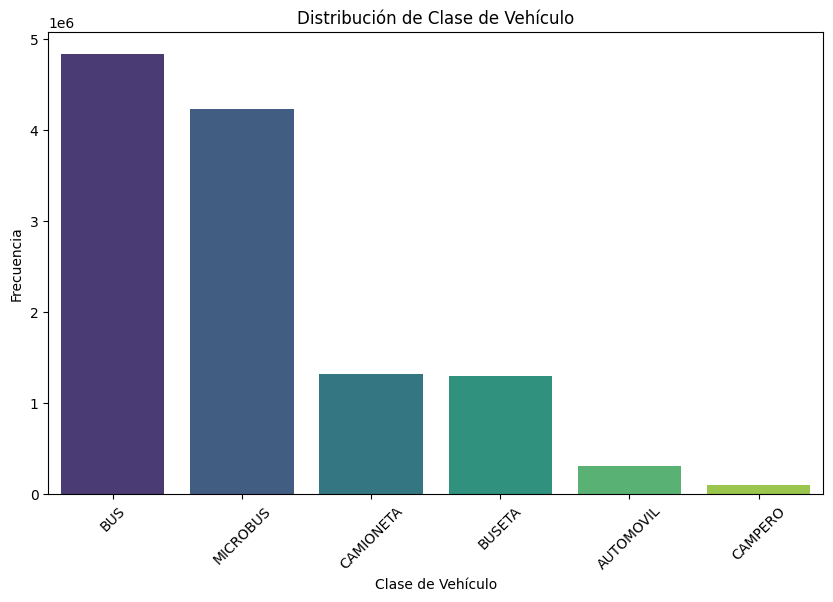

In [ ]:
print('### Columna: `clase_vehiculo`')
clase_vehiculo_counts = df['clase_vehiculo'].value_counts()
clase_vehiculo_proportions = df['clase_vehiculo'].value_counts(normalize=True).mul(100).round(2)

clase_vehiculo_df = pd.DataFrame({
    'Count': clase_vehiculo_counts,
    'Proportion (%)': clase_vehiculo_proportions
})
display(clase_vehiculo_df)

plt.figure(figsize=(10, 6))
sns.barplot(x=clase_vehiculo_counts.index, y=clase_vehiculo_counts.values, palette='viridis')
plt.title('Distribución de Clase de Vehículo')
plt.xlabel('Clase de Vehículo')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45)
plt.show()

### Columna: `nivel_servicio`


,Count,Proportion (%)
nivel_servicio,,
LUJO,6933096,57.34
BASICO,5157470,42.65
PREFERENCIAL DE LUJO,1615,0.01


/tmp/ipykernel_3481/768147719.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=nivel_servicio_counts.index, y=nivel_servicio_counts.values, palette='plasma')


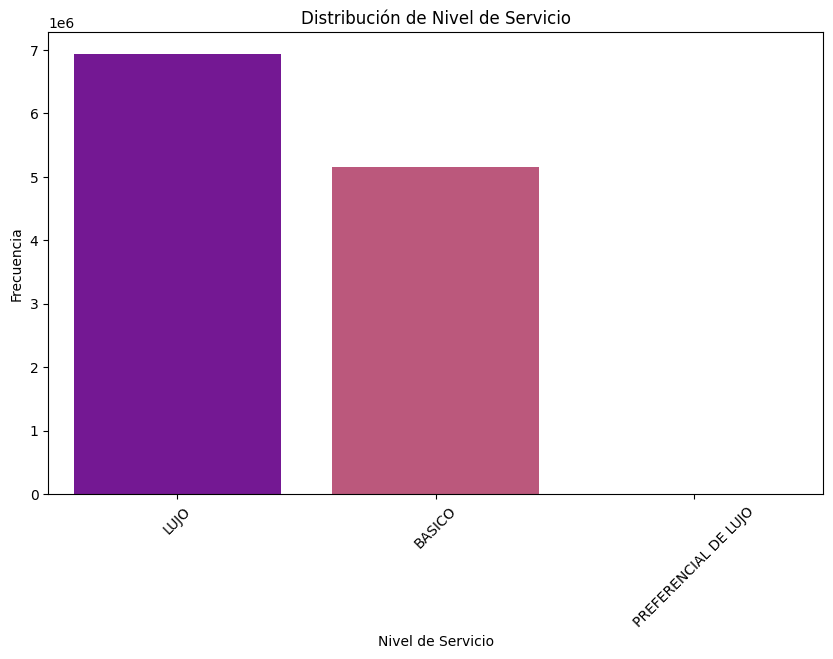

In [ ]:
print('### Columna: `nivel_servicio`')
nivel_servicio_counts = df['nivel_servicio'].value_counts()
nivel_servicio_proportions = df['nivel_servicio'].value_counts(normalize=True).mul(100).round(2)

nivel_servicio_df = pd.DataFrame({
    'Count': nivel_servicio_counts,
    'Proportion (%)': nivel_servicio_proportions
})
display(nivel_servicio_df)

plt.figure(figsize=(10, 6))
sns.barplot(x=nivel_servicio_counts.index, y=nivel_servicio_counts.values, palette='plasma')
plt.title('Distribución de Nivel de Servicio')
plt.xlabel('Nivel de Servicio')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45)
plt.show()

### Columna: `tipo_despacho`


,Count,Proportion (%)
tipo_despacho,,
ORIGEN,9155508,75.71
TRANSITO,2936673,24.29


/tmp/ipykernel_3481/2600637301.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tipo_despacho_counts.index, y=tipo_despacho_counts.values, palette='magma')


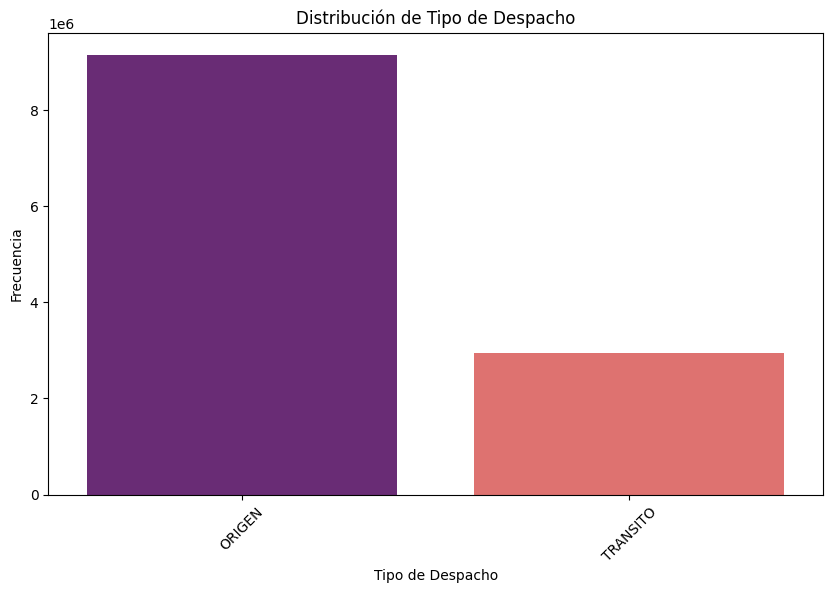

In [ ]:
print('### Columna: `tipo_despacho`')
tipo_despacho_counts = df['tipo_despacho'].value_counts()
tipo_despacho_proportions = df['tipo_despacho'].value_counts(normalize=True).mul(100).round(2)

tipo_despacho_df = pd.DataFrame({
    'Count': tipo_despacho_counts,
    'Proportion (%)': tipo_despacho_proportions
})
display(tipo_despacho_df)

plt.figure(figsize=(10, 6))
sns.barplot(x=tipo_despacho_counts.index, y=tipo_despacho_counts.values, palette='magma')
plt.title('Distribución de Tipo de Despacho')
plt.xlabel('Tipo de Despacho')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45)
plt.show()

### Columna: `terminal`


,Count,Proportion (%)
terminal,,
T.T. DE BOGOTÁ SALITRE,1061310,8.78
T.T. DE CALI,900708,7.45
T.T. DE MEDELLÍN NORTE,644898,5.33
T.T. DE ARMENIA,570143,4.71
T.T. DE PEREIRA,552600,4.57


/tmp/ipykernel_3481/3667265819.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=terminal_counts.index, y=terminal_counts.values, palette='cividis')


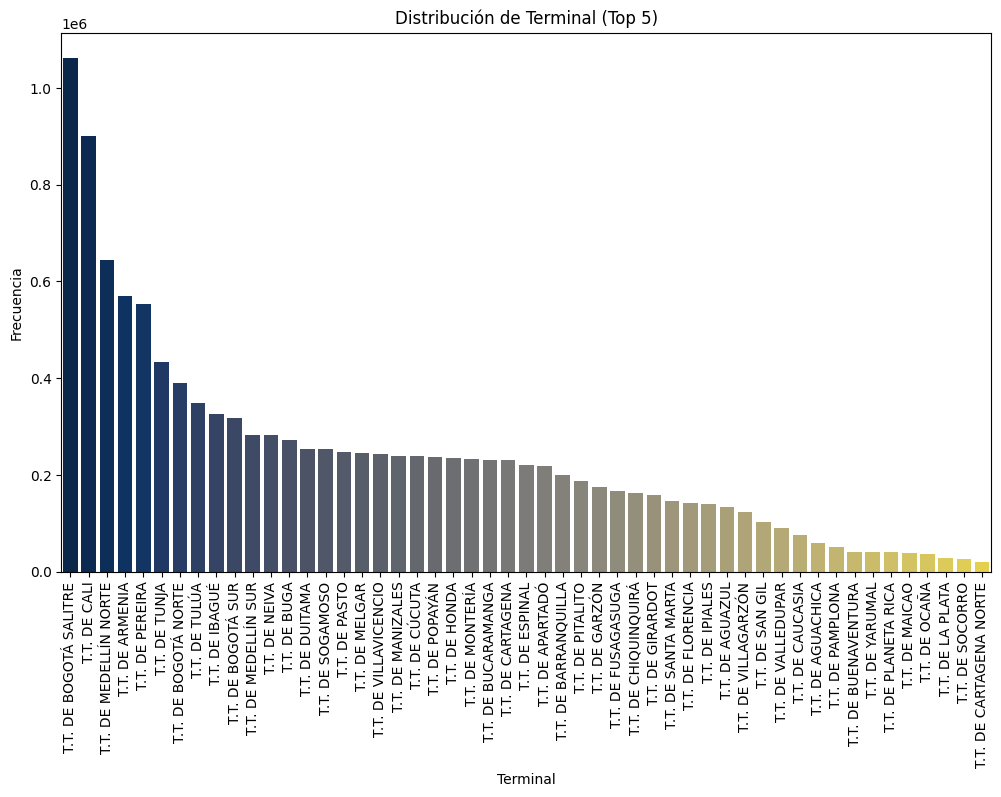

In [ ]:
print('### Columna: `terminal`')
terminal_counts = df['terminal'].value_counts()
terminal_proportions = df['terminal'].value_counts(normalize=True).mul(100).round(2)

terminal_df = pd.DataFrame({
    'Count': terminal_counts,
    'Proportion (%)': terminal_proportions
})
display(terminal_df.head())

plt.figure(figsize=(12, 7))
sns.barplot(x=terminal_counts.index, y=terminal_counts.values, palette='cividis')
plt.title('Distribución de Terminal (Top 5)')
plt.xlabel('Terminal')
plt.ylabel('Frecuencia')
plt.xticks(rotation=90)
plt.show()

## Análisis de Relación entre Variables Cualitativas (Tablas de Contingencia)

Tabla de Contingencia (Clase de Vehículo vs Nivel de Servicio):


nivel_servicio,BASICO,LUJO,PREFERENCIAL DE LUJO
clase_vehiculo,,,
AUTOMOVIL,178524,129441,0
BUS,1512123,3321806,1131
BUSETA,501715,795805,404
CAMIONETA,947341,371244,11
CAMPERO,19023,79051,0
MICROBUS,1998744,2235749,69


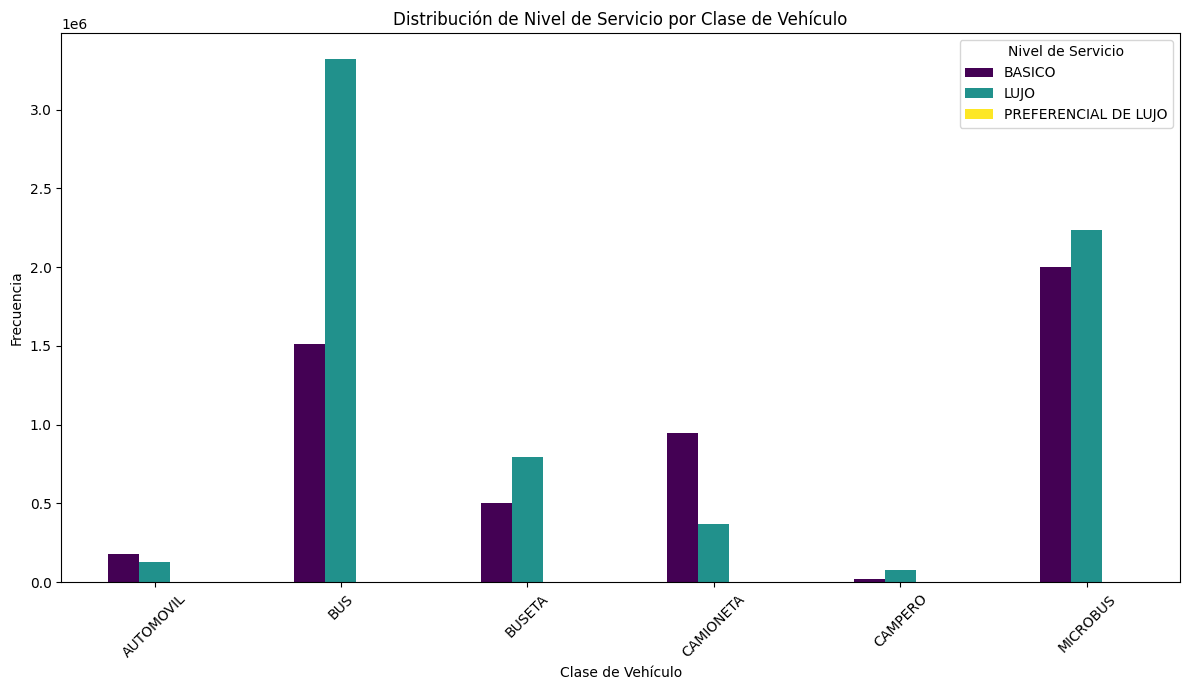

In [ ]:
print('Tabla de Contingencia (Clase de Vehículo vs Nivel de Servicio):')
contingency_table = pd.crosstab(df['clase_vehiculo'], df['nivel_servicio'])
display(contingency_table)

# Crear un gráfico de barras agrupadas
contingency_table.plot(kind='bar', figsize=(12, 7), colormap='viridis')
plt.title('Distribución de Nivel de Servicio por Clase de Vehículo')
plt.xlabel('Clase de Vehículo')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45)
plt.legend(title='Nivel de Servicio')
plt.tight_layout()
plt.show()